<a href="https://colab.research.google.com/github/riyag25/Almabetter/blob/main/Capstone_Project_EDA_PlayStoreAppReviewAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Play Store App Review Analysis
##Business Context

The Play Store apps data has enormous potential to drive app-making businesses to success. Actionable insights can be drawn for developers to work on and capture the Android market. Each app (row) has values for category, rating, size, and more. Another dataset contains customer reviews of the android apps. Explore and analyse the data to discover key factors responsible for app engagement and success.

## Business Objective
To analyse Play store app data and discover key factors responsible for app engagement and app success. These insights will help developers, managers and stakeholders to make data driven decisions to improve app development,customer satisfaction, pricing, revenue genration etc.

##Problem Statement
1. Do free apps have more installs than paid apps?
2. Which genre of apps have higher rating? .
3. Which age group have more installs? Which genre do they prefer?





# Data Download

In [ ]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import regex as re

# Set plot style
sns.set(style='whitegrid')
%matplotlib inline


In [ ]:
import gdown
url_id = "1pVZNhpwbqbu3xLf6J-1KrQI_-B8KqDCt"
# direct download link format:
url_playStore = f"https://drive.google.com/uc?id={url_id}"

review_file_id = "1zJmyrNtkv_ZnVAY1wtg1irTRbpoZ9rRH"
url_review = f"https://drive.google.com/uc?id={review_file_id}"

apps = "playStore.csv"  # name you want to save as
gdown.download(url_playStore, apps, quiet=False)

review = 'review.csv'
review = gdown.download(url_review, review, quiet=False )
# Then load it, e.g. with pandas:
import pandas as pd
apps_df = pd.read_csv(apps)
reviews_df = pd.read_csv(review)

Downloading...
From: https://drive.google.com/uc?id=1pVZNhpwbqbu3xLf6J-1KrQI_-B8KqDCt
To: /content/playStore.csv
100%|██████████| 1.36M/1.36M [00:00<00:00, 141MB/s]
Downloading...
From: https://drive.google.com/uc?id=1zJmyrNtkv_ZnVAY1wtg1irTRbpoZ9rRH
To: /content/review.csv
100%|██████████| 7.67M/7.67M [00:00<00:00, 24.1MB/s]


In [ ]:
# Display basic info
print("Apps Dataset Shape:", apps_df.shape)
print("\nReviews Dataset Shape:", reviews_df.shape)
print("\nApps Columns:", apps_df.columns.tolist())
print("\nReviews Columns:", reviews_df.columns.tolist())

Apps Dataset Shape: (10841, 13)

Reviews Dataset Shape: (64295, 5)

Apps Columns: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Reviews Columns: ['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


## Data Cleaning

In [ ]:
apps_df.head()


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
reviews_df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [ ]:
#drop duplicates
apps_df.drop_duplicates(inplace=True)
reviews_df.drop_duplicates(inplace=True)

In [ ]:
# Display initial info
print("Initial Apps Dataset Info:")
print(apps_df.info())
print("\nMissing Values:\n", apps_df.isnull().sum())

Initial Apps Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 10358 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10358 non-null  object 
 1   Category        10358 non-null  object 
 2   Rating          8893 non-null   float64
 3   Reviews         10358 non-null  object 
 4   Size            10358 non-null  object 
 5   Installs        10358 non-null  object 
 6   Type            10357 non-null  object 
 7   Price           10358 non-null  object 
 8   Content Rating  10357 non-null  object 
 9   Genres          10358 non-null  object 
 10  Last Updated    10358 non-null  object 
 11  Current Ver     10350 non-null  object 
 12  Android Ver     10355 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB
None

Missing Values:
 App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Ins

In [ ]:
apps_df['Category'].value_counts()

,count
Category,
FAMILY,1943
GAME,1121
TOOLS,843
BUSINESS,427
MEDICAL,408
PRODUCTIVITY,407
PERSONALIZATION,388
LIFESTYLE,373
COMMUNICATION,366


In [ ]:
apps_df['Size'].str.extract('(\d+\.?\d*)').astype(float)

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-1193959030.py:1: SyntaxWarning: invalid escape sequence '\d'
  apps_df['Size'].str.extract('(\d+\.?\d*)').astype(float)


,0
0,19.0
1,14.0
2,8.7
3,25.0
4,2.8
...,...
10836,53.0
10837,3.6
10838,9.5
10839,NaN


In [ ]:
valid_categories = [apps_df['Category'].value_counts().index[i] for i in range(len(apps_df['Category'].value_counts()))]
valid_categories

['FAMILY',
 'GAME',
 'TOOLS',
 'BUSINESS',
 'MEDICAL',
 'PRODUCTIVITY',
 'PERSONALIZATION',
 'LIFESTYLE',
 'COMMUNICATION',
 'FINANCE',
 'SPORTS',
 'PHOTOGRAPHY',
 'HEALTH_AND_FITNESS',
 'SOCIAL',
 'NEWS_AND_MAGAZINES',
 'TRAVEL_AND_LOCAL',
 'BOOKS_AND_REFERENCE',
 'SHOPPING',
 'DATING',
 'VIDEO_PLAYERS',
 'MAPS_AND_NAVIGATION',
 'EDUCATION',
 'FOOD_AND_DRINK',
 'ENTERTAINMENT',
 'LIBRARIES_AND_DEMO',
 'AUTO_AND_VEHICLES',
 'WEATHER',
 'HOUSE_AND_HOME',
 'ART_AND_DESIGN',
 'EVENTS',
 'PARENTING',
 'COMICS',
 'BEAUTY',
 '1.9']

In [ ]:
valid_categories.remove('1.9')


In [ ]:
# Function to convert Reviews with 'M' or 'K' suffixes
def convert_reviews(review):
    try:
        review = str(review).strip()
        if review.endswith('M'):
            return float(review.replace('M', '')) * 1_000_000
        elif review.endswith('K'):
            return float(review.replace('K', '')) * 1_000
        return float(review.replace(',', ''))
    except (ValueError, TypeError):
        return np.nan

# Function to convert Size to MB
def convert_size(size):
    try:
        size = str(size).strip()
        if size == 'Varies with device':
            return np.nan
        # Extract numeric part (e.g., '19M' -> 19)
        match = re.match(r'(\d+\.?\d*)[Mk]?', size)
        if not match:
            return np.nan
        value = float(match.group(1))
        if size.endswith('k'):
            return value / 1000  # Convert KB to MB
        elif size.endswith('M'):
            return value
        return value  # Assume MB if no suffix
    except (ValueError, TypeError):
        return np.nan

# Function to convert Price
def convert_price(price):
    try:
        price = str(price).strip()
        if price == '0' or price == 'Free':
            return 0.0
        return float(price.replace('$', ''))
    except (ValueError, TypeError):
        return np.nan

# Function to flag invalid apps
def flag_invalid_apps(df):
    df = df.copy()
    df['Invalid_Flag'] = False
    df['Invalid_Reason'] = ''

    # Rule 1: Missing critical columns
    critical_cols = ['App', 'Category', 'Rating']
    for col in critical_cols:
        df.loc[df[col].isnull(), 'Invalid_Flag'] = True
        df.loc[df[col].isnull(), 'Invalid_Reason'] += f'Missing {col};'

    # Rule 2: Invalid Category
    df.loc[~df['Category'].isin(valid_categories), 'Invalid_Flag'] = True
    df.loc[~df['Category'].isin(valid_categories), 'Invalid_Reason'] += 'Invalid Category;'

    # Rule 3: Invalid Rating
    df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
    df.loc[(df['Rating'] < 1.0) | (df['Rating'] > 5.0), 'Invalid_Flag'] = True
    df.loc[(df['Rating'] < 1.0) | (df['Rating'] > 5.0), 'Invalid_Reason'] += 'Rating out of range;'

    # Rule 4: Invalid Reviews
    df['Reviews'] = df['Reviews'].apply(convert_reviews)
    df.loc[df['Reviews'].isna() | (df['Reviews'] < 0), 'Invalid_Flag'] = True
    df.loc[df['Reviews'].isna() | (df['Reviews'] < 0), 'Invalid_Reason'] += 'Invalid Reviews;'

    # Rule 5: Invalid Installs
    df['Installs'] = df['Installs'].astype(str).str.replace('+', '').str.replace(',', '')
    df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')
    df.loc[df['Installs'].isna() | (df['Installs'] < 0), 'Invalid_Flag'] = True
    df.loc[df['Installs'].isna() | (df['Installs'] < 0), 'Invalid_Reason'] += 'Invalid Installs;'

    # Rule 6: Reviews > Installs
    df.loc[df['Reviews'] > df['Installs'], 'Invalid_Flag'] = True
    df.loc[df['Reviews'] > df['Installs'], 'Invalid_Reason'] += 'Reviews exceed Installs;'

    # Rule 7: Invalid Size
    df['Size'] = df['Size'].apply(convert_size)
    df.loc[(df['Size'].isna()) & (df['Size'] != 'Varies with device'), 'Invalid_Flag'] = True
    df.loc[(df['Size'].isna()) & (df['Size'] != 'Varies with device'), 'Invalid_Reason'] += 'Invalid Size;'

    # Rule 8: Invalid Price
    df['Price'] = df['Price'].apply(convert_price)
    df.loc[df['Price'].isna() | (df['Price'] < 0), 'Invalid_Flag'] = True
    df.loc[df['Price'].isna() | (df['Price'] < 0), 'Invalid_Reason'] += 'Invalid Price;'

    # Rule 9: Duplicate App names with inconsistent metadata
    duplicates = df[df.duplicated(subset=['App'], keep=False)]
    if not duplicates.empty:
        inconsistent = duplicates.groupby('App').filter(lambda x: x['Category'].nunique() > 1 or x['Rating'].nunique() > 1)
        df.loc[df['App'].isin(inconsistent['App']), 'Invalid_Flag'] = True
        df.loc[df['App'].isin(inconsistent['App']), 'Invalid_Reason'] += 'Inconsistent duplicate App;'

    return df

# Apply cleaning and validation
apps_df_clean = flag_invalid_apps(apps_df)

# Summarize invalid apps
invalid_apps = apps_df_clean[apps_df_clean['Invalid_Flag']]
print(f"Total Invalid Apps: {len(invalid_apps)}")
print("\nInvalid Apps Summary (First 5):\n")
print(invalid_apps[['App', 'Category', 'Rating', 'Reviews', 'Installs', 'Invalid_Reason']].head())

# Save invalid apps to CSV
invalid_apps.to_csv('invalid_apps.csv', index=False)
print("\nInvalid apps saved to 'invalid_apps.csv'")

# Proceed with cleaned data (remove invalid apps)
cleaned_apps_df = apps_df_clean[~apps_df_clean['Invalid_Flag']].copy()



Total Invalid Apps: 3122

Invalid Apps Summary (First 5):

                                               App        Category  Rating  \
1                              Coloring book moana  ART_AND_DESIGN     3.9   
23                          Mcqueen Coloring pages  ART_AND_DESIGN     NaN   
36  UNICORN - Color By Number & Pixel Art Coloring  ART_AND_DESIGN     4.7   
37                              Floor Plan Creator  ART_AND_DESIGN     4.1   
42                      Textgram - write on photos  ART_AND_DESIGN     4.4   

     Reviews    Installs                              Invalid_Reason  
1      967.0    500000.0                 Inconsistent duplicate App;  
23      61.0    100000.0  Missing Rating;Inconsistent duplicate App;  
36    8145.0    500000.0                 Inconsistent duplicate App;  
37   36639.0   5000000.0                               Invalid Size;  
42  295221.0  10000000.0                               Invalid Size;  

Invalid apps saved to 'invalid_apps.csv'


In [ ]:
# Impute missing values for further analysis
cleaned_apps_df['Rating'] = cleaned_apps_df['Rating'].fillna(cleaned_apps_df['Rating'].median())
cleaned_apps_df['Size'] = cleaned_apps_df['Size'].fillna(cleaned_apps_df['Size'].median())
cleaned_apps_df['Type'] = cleaned_apps_df['Type'].fillna('Free')
cleaned_apps_df['Content Rating'] = cleaned_apps_df['Content Rating'].fillna('Everyone')

print(f"\nCleaned Dataset Shape: {cleaned_apps_df.shape}")


Cleaned Dataset Shape: (7236, 15)


In [ ]:
#Save cleaned dataset to google drive and load data from google drive
cleaned_apps_df.to_csv('cleaned_apps_df.csv', index=False)


In [ ]:
# Join the apps and reviews dataframes
df_merged = cleaned_apps_df.merge(reviews_df, on='App', how='inner')


In [ ]:
df_merged.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Invalid_Flag,Invalid_Reason,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,Garden Coloring Book,ART_AND_DESIGN,4.4,13791.0,33.0,1000000.0,Free,0.0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up,False,,It's...a coloring book ap. And I like adult co...,Positive,2.166667e-01,0.573810
1,Garden Coloring Book,ART_AND_DESIGN,4.4,13791.0,33.0,1000000.0,Free,0.0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up,False,,wanted access pictures. I denied let app. Don'...,Neutral,0.000000e+00,0.000000
2,Garden Coloring Book,ART_AND_DESIGN,4.4,13791.0,33.0,1000000.0,Free,0.0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up,False,,Way many ads... im paying 8$USD pictures color...,Positive,3.000000e-01,0.600000
3,Garden Coloring Book,ART_AND_DESIGN,4.4,13791.0,33.0,1000000.0,Free,0.0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up,False,,"good bad color outside lines. like real, tradi...",Positive,2.775558e-17,0.579167
4,Garden Coloring Book,ART_AND_DESIGN,4.4,13791.0,33.0,1000000.0,Free,0.0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up,False,,I really enjoying application. My complaint sm...,Negative,-3.472222e-02,0.581944


Descriptive Statistics:


,Rating,Size,Installs,Price,Reviews
count,7236.000000,7236.000000,7.236000e+03,7236.000000,7.236000e+03
mean,4.165437,22.292405,6.558685e+06,1.139747,1.888712e+05
std,0.553652,23.073569,4.284319e+07,17.935364,1.114957e+06
min,1.000000,0.008500,5.000000e+00,0.000000,1.000000e+00
25%,4.000000,5.000000,1.000000e+04,0.000000,9.200000e+01
50%,4.300000,14.000000,1.000000e+05,0.000000,1.877500e+03
75%,4.500000,32.000000,1.000000e+06,0.000000,3.234450e+04
max,5.000000,100.000000,1.000000e+09,400.000000,2.772535e+07


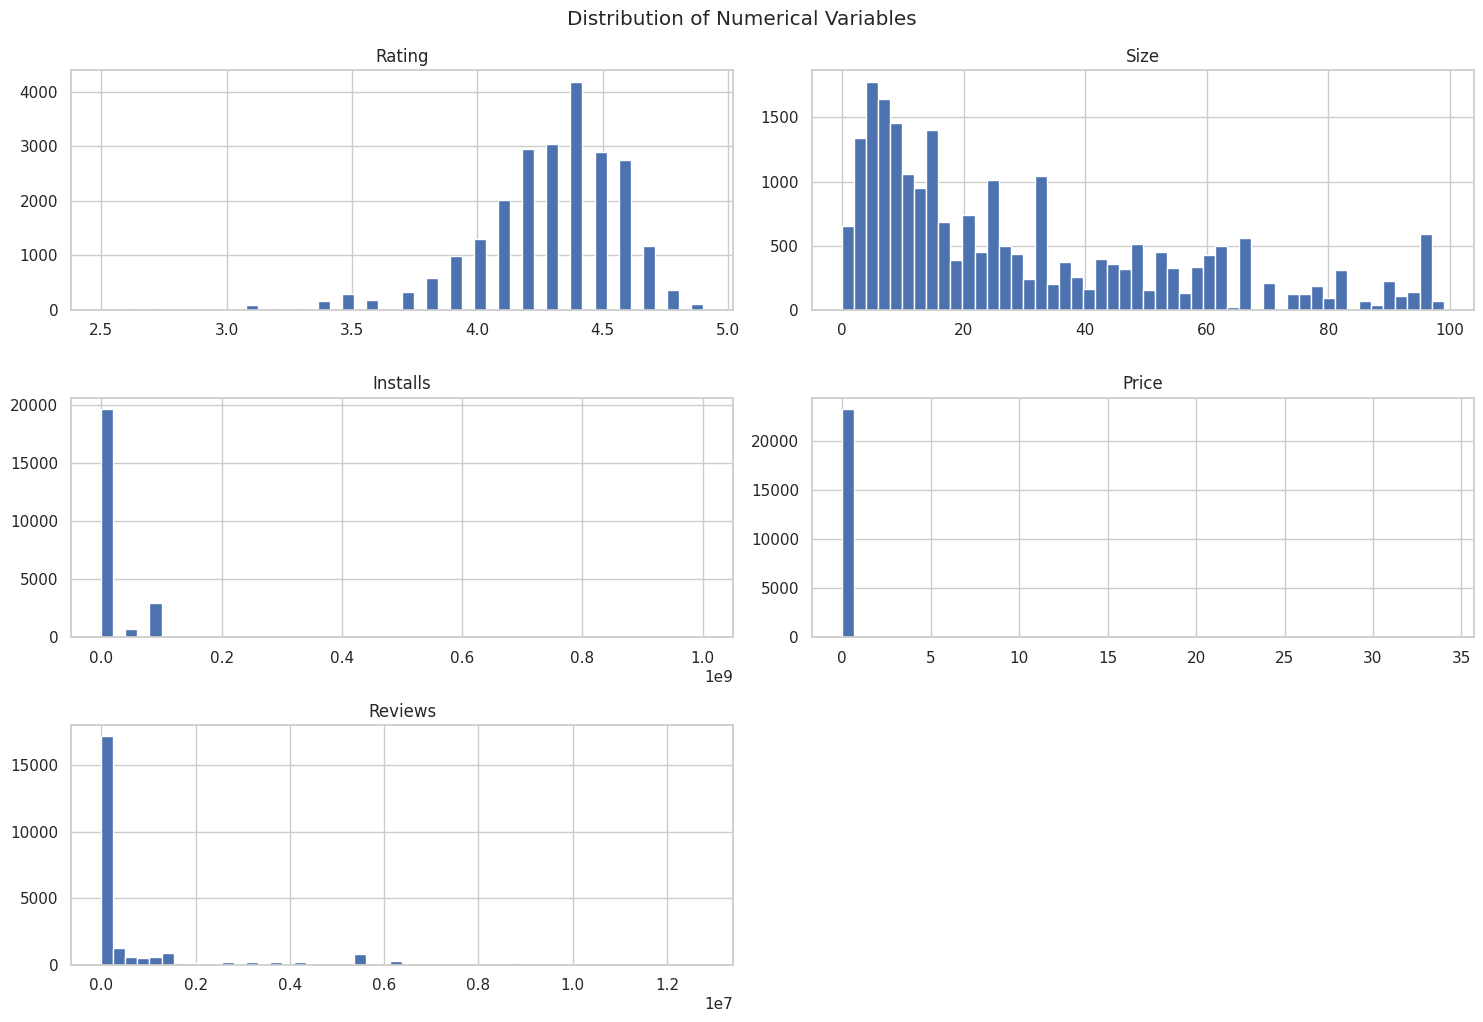

In [ ]:
# Univariate Analysis of key numerical columns

# Select numerical columns for analysis
numerical_cols = ['Rating', 'Size', 'Installs', 'Price', 'Reviews']

# Descriptive statistics for numerical columns
print("Descriptive Statistics:")
display(cleaned_apps_df[numerical_cols].describe())

# Histograms for numerical columns
df_merged[numerical_cols].hist(bins=50, figsize=(15, 10))
plt.tight_layout()
plt.suptitle('Distribution of Numerical Variables', y=1.02)
plt.show()

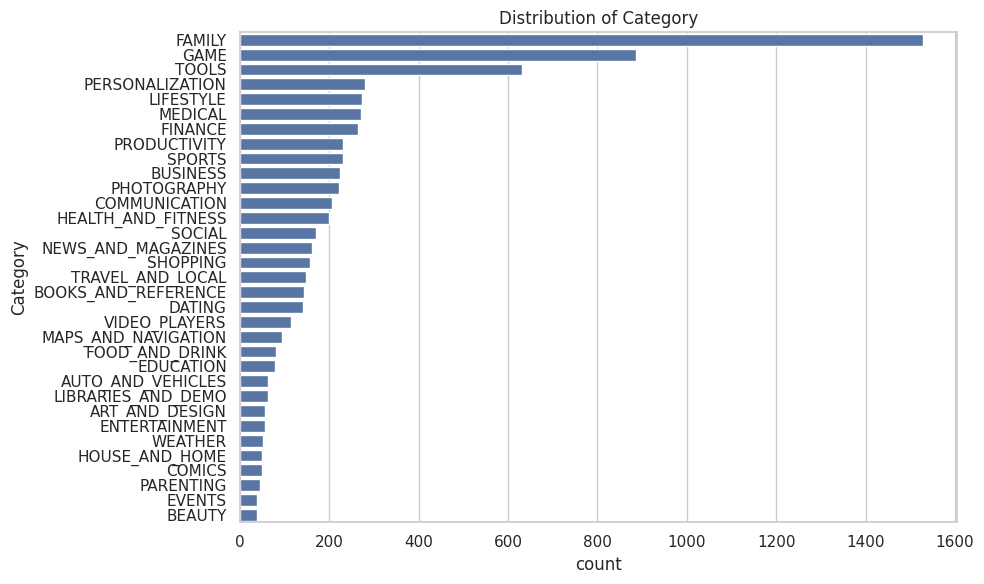

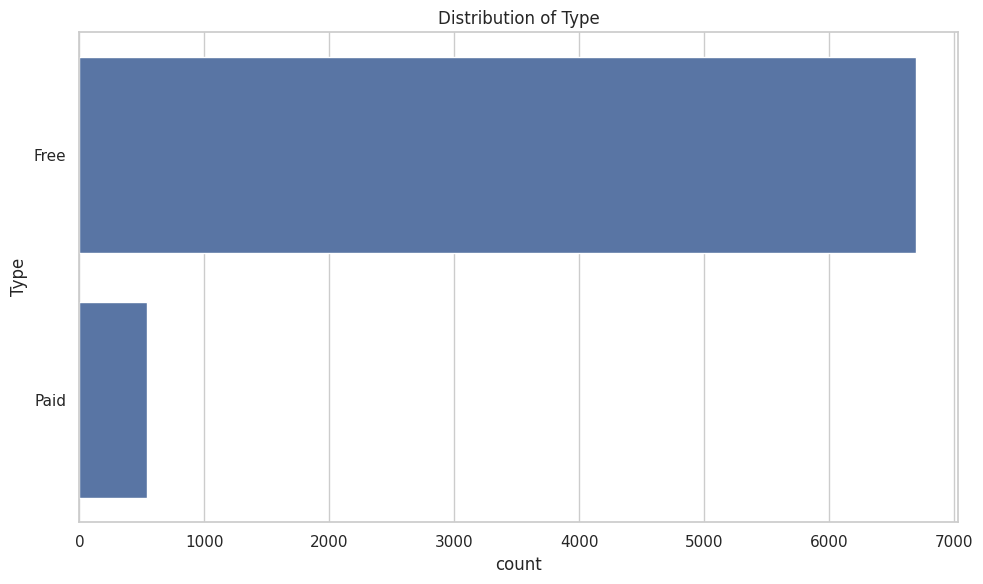

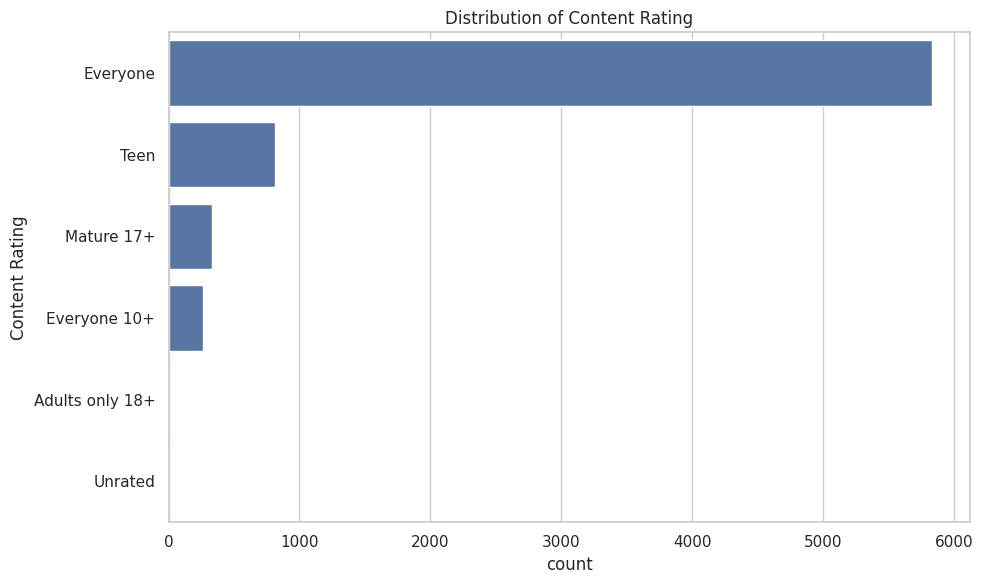

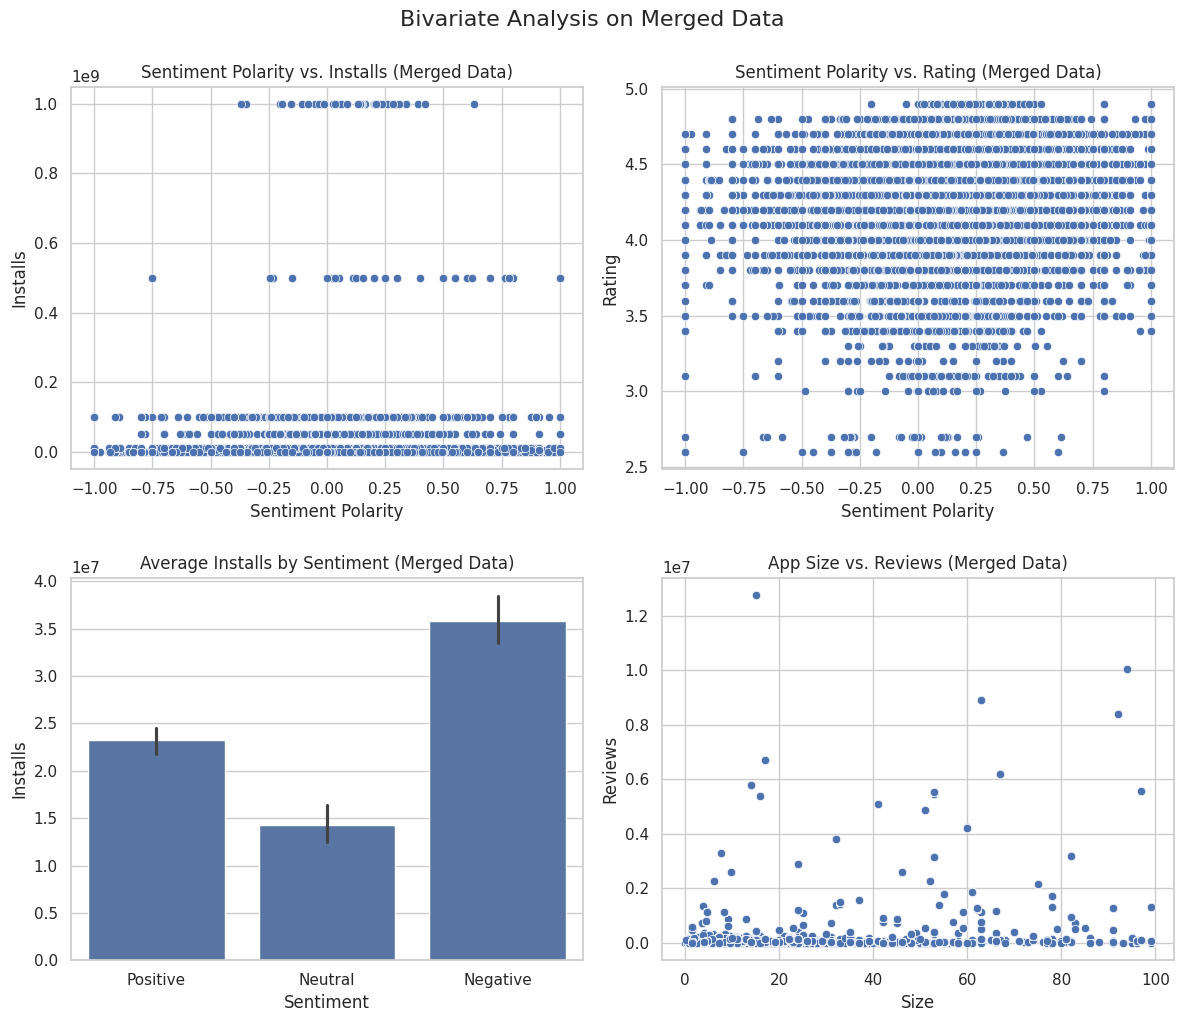

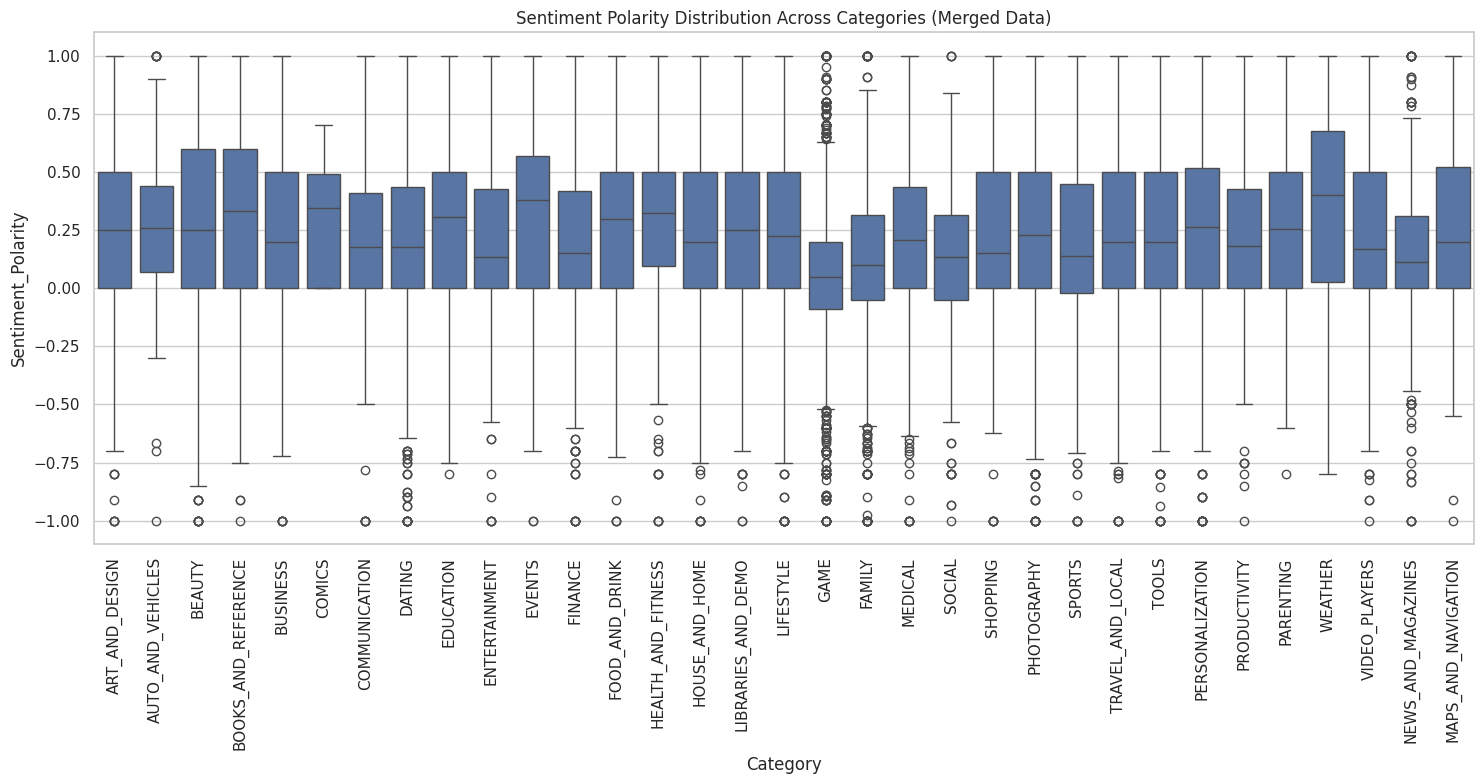

In [ ]:
# Bivariate Analysis on Merged Data - Grid Layout

fig, axes = plt.subplots(2, 2, figsize=(12, 10)) # Create a 2x2 grid of subplots

# Installs vs. Sentiment Polarity
sns.scatterplot(x='Sentiment_Polarity', y='Installs', data=df_merged, ax=axes[0, 0])
axes[0, 0].set_title('Sentiment Polarity vs. Installs (Merged Data)')
axes[0, 0].set_xlabel('Sentiment Polarity')
axes[0, 0].set_ylabel('Installs')

# Rating vs. Sentiment Polarity
sns.scatterplot(x='Sentiment_Polarity', y='Rating', data=df_merged, ax=axes[0, 1])
axes[0, 1].set_title('Sentiment Polarity vs. Rating (Merged Data)')
axes[0, 1].set_xlabel('Sentiment Polarity')
axes[0, 1].set_ylabel('Rating')

# Installs vs. Sentiment (using bar plot for comparison)
sns.barplot(x='Sentiment', y='Installs', data=df_merged, ax=axes[1, 0])
axes[1, 0].set_title('Average Installs by Sentiment (Merged Data)')
axes[1, 0].set_xlabel('Sentiment')
axes[1, 0].set_ylabel('Installs')

# Size vs. Reviews
sns.scatterplot(x='Size', y='Reviews', data=df_merged, ax=axes[1, 1])
axes[1, 1].set_title('App Size vs. Reviews (Merged Data)')
axes[1, 1].set_xlabel('Size')
axes[1, 1].set_ylabel('Reviews')


plt.tight_layout()
plt.suptitle('Bivariate Analysis on Merged Data', y=1.02, fontsize=16)
plt.show()

# Keeping the Category vs. Sentiment plot separate for better visualization
plt.figure(figsize=(15, 8))
sns.boxplot(x='Category', y='Sentiment_Polarity', data=df_merged)
plt.xticks(rotation=90)
plt.title('Sentiment Polarity Distribution Across Categories (Merged Data)')
plt.tight_layout()
plt.show()

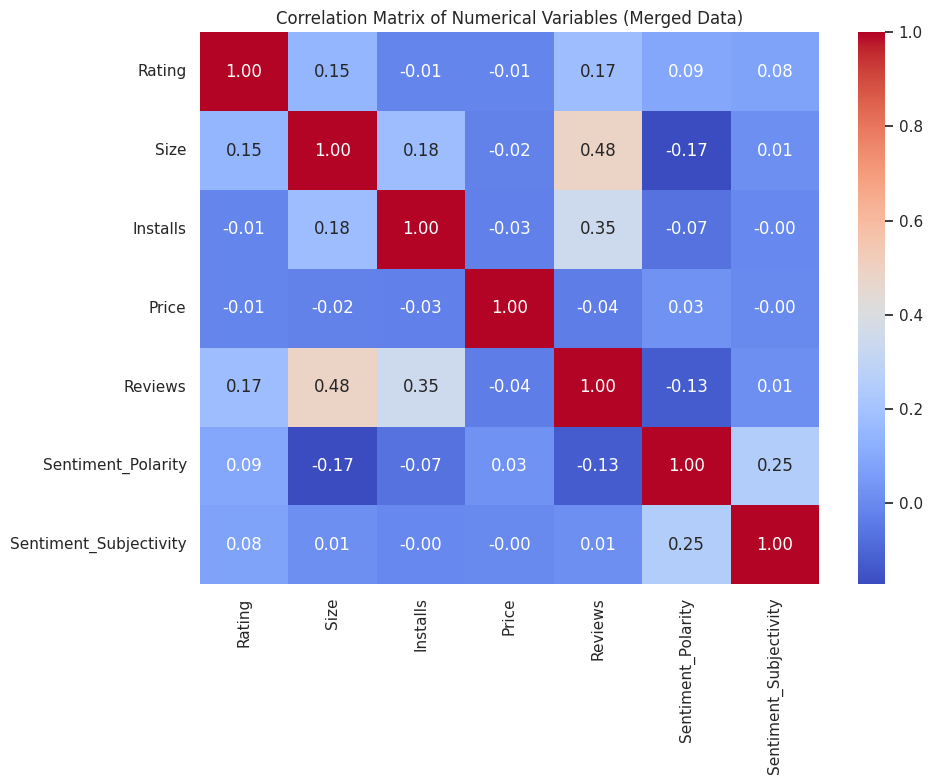

In [ ]:

# Correlation Analysis on the merged dataframe
numerical_cols_merged = ['Rating', 'Size', 'Installs', 'Price', 'Reviews', 'Sentiment_Polarity', 'Sentiment_Subjectivity']
correlation_matrix_merged = df_merged[numerical_cols_merged].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix_merged, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Variables (Merged Data)')
plt.tight_layout()
plt.show()

In [ ]:
reviews_df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


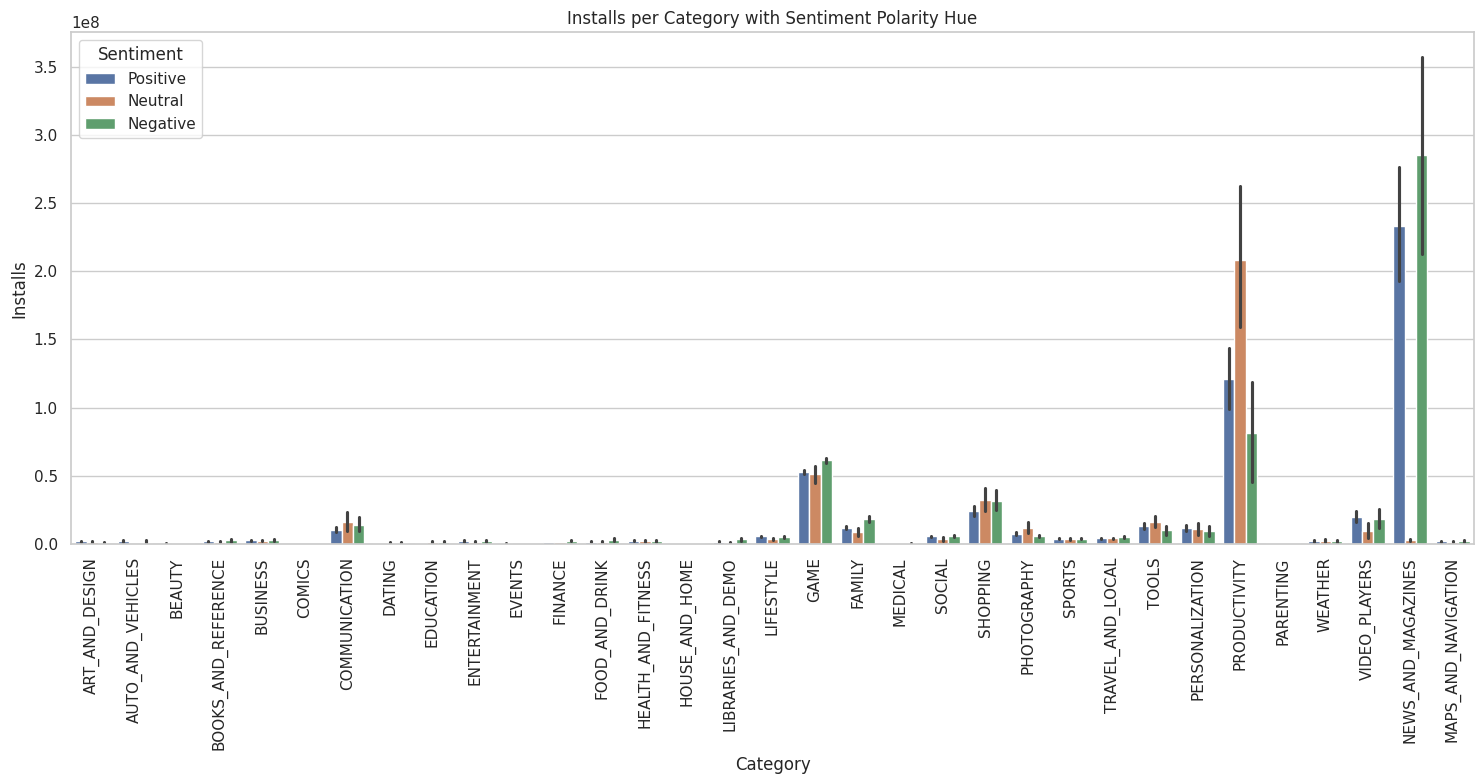

In [ ]:
# Category wise barplot on number of installs and hue based on sentiment polarity
plt.figure(figsize=(15, 8))
sns.barplot(x='Category', y='Installs', hue='Sentiment', data=df_merged)
plt.xticks(rotation=90)
plt.title('Installs per Category with Sentiment Polarity Hue')
plt.tight_layout()
plt.show()

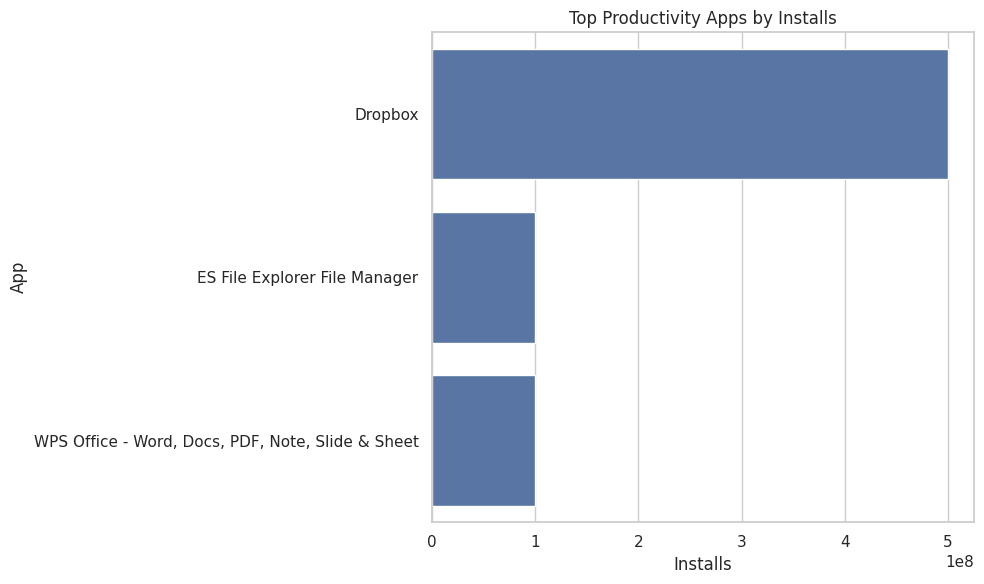

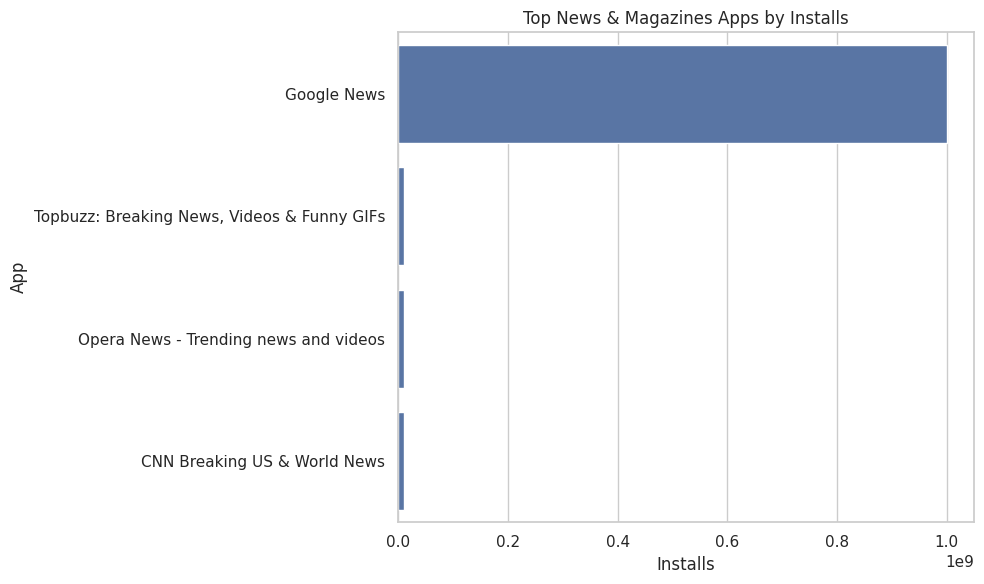

In [ ]:
# Filter for Productivity and News & Magazines categories
productivity_apps = cleaned_apps_df[cleaned_apps_df['Category'] == 'PRODUCTIVITY'].copy()
news_apps = cleaned_apps_df[cleaned_apps_df['Category'] == 'NEWS_AND_MAGAZINES'].copy()

# Get top 5 apps by installs in each category
top_productivity = productivity_apps.sort_values(by='Installs', ascending=False).head(6)
top_news = news_apps.sort_values(by='Installs', ascending=False).head(6)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x='Installs', y='App', data=top_productivity)
plt.title('Top Productivity Apps by Installs')
plt.xlabel('Installs')
plt.ylabel('App')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(x='Installs', y='App', data=top_news)
plt.title('Top News & Magazines Apps by Installs')
plt.xlabel('Installs')
plt.ylabel('App')
plt.tight_layout()
plt.show()

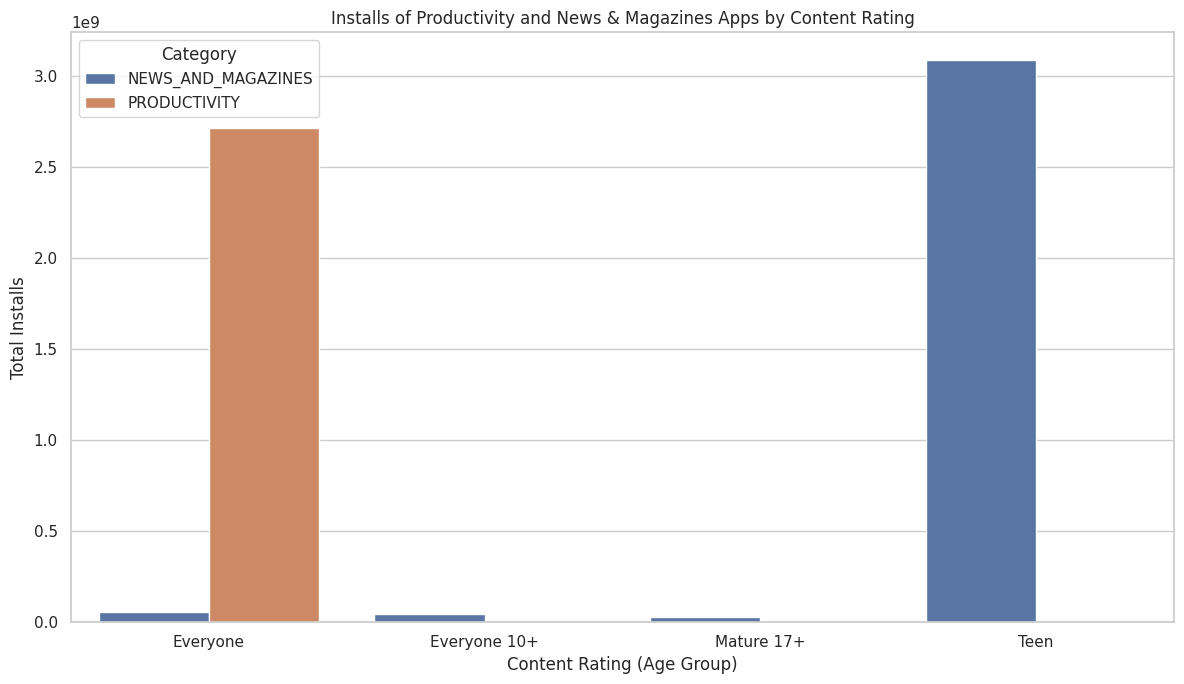

In [ ]:
# Filter for Productivity and News & Magazines categories
productivity_news_apps = cleaned_apps_df[cleaned_apps_df['Category'].isin(['PRODUCTIVITY', 'NEWS_AND_MAGAZINES'])].copy()

# Group by Content Rating and Category and sum installs
installs_by_content_rating_category = productivity_news_apps.groupby(['Content Rating', 'Category'])['Installs'].sum().reset_index()

# Plotting
plt.figure(figsize=(12, 7))
sns.barplot(x='Content Rating', y='Installs', hue='Category', data=installs_by_content_rating_category)
plt.title('Installs of Productivity and News & Magazines Apps by Content Rating')
plt.xlabel('Content Rating (Age Group)')
plt.ylabel('Total Installs')
plt.tight_layout()
plt.show()

# KEY FINDINGS

1.	Number of free apps are more compared to paid apps.But there is no direct corelation between price and installs. So pricing for the app can be considered for better revenues.

2.   Size is not a factor for App installs . Developers can fix a max allocated size and focus more on user experience .
3.  Most people are preferring apps in news and magazines category, followed by Productivity apps.
4. Top in Productivity apps is Dropbox, and in news and magazine category Google News.

5. News and Magazine apps are mostly preferred by Teens, while productivity apps are preferred  by everyone.



